# 03 · Video baselines

**Question:** can learned video representations predict repetitions remaining?

Run All displays saved results. Training and model export are off by default. These are video-derived RIR targets, not direct physiological fatigue measurements.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "training/notebooks").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from training.reporting import (
    RUNS, LABELS, result_folder, load_predictions, assert_matched_examples,
    regression_report, classification_report, metrics_table,
    plot_errors, plot_participants, plot_diagnostics, plot_warnings,
)
OUTPUT = ROOT / "training/artifacts/submission_report"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 44)


## Experiment 1 · Original framing

**Why:** establish a reference before adding complexity.  
**Change:** frozen ResNet frame features followed by a trainable TCN or LSTM; compare against a training-median prediction.  
**Test:** 124 reps, nine clips, six people; test people are excluded from training.

In [2]:
original_predictions = load_predictions(ROOT, "original", "Original framing")
original_scores, original_people = regression_report(original_predictions)
display(metrics_table(original_scores))


,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Original framing,ResNet + LSTM,124,6,3,4.941,0.126,5.989,0.137,0.267,-1.561,-1.152,6
1,Original framing,ResNet + TCN,124,6,3,5.590,0.678,6.507,0.103,0.227,0.219,-2.615,6
2,Original framing,Training median,124,6,3,4.845,0.000,5.883,0.209,0.348,-0.532,-1.086,6


**Result:** LSTM MAE ≈ 4.94 versus 4.84 for the median reference. Neither neural model beat the reference.  
**Next question:** is background distracting the image representation?

## Experiment 2 · Whole-lifter crops

**Why:** reduce background while keeping the lifter visible.  
**Change:** use verified crop copies; keep labels, repetitions and participant splits matched. Crops were chosen retrospectively across full clips.

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Original framing,ResNet + LSTM,124,6,3,4.941,0.126,5.989,0.137,0.267,-1.561,-1.152,6
1,Original framing,ResNet + TCN,124,6,3,5.590,0.678,6.507,0.103,0.227,0.219,-2.615,6
2,Original framing,Training median,124,6,3,4.845,0.000,5.883,0.209,0.348,-0.532,-1.086,6
3,Whole-lifter crop,ResNet + LSTM,124,6,3,4.909,0.207,5.942,0.111,0.263,-1.052,-1.088,6
4,Whole-lifter crop,ResNet + TCN,124,6,3,4.998,0.164,5.939,0.120,0.245,-0.550,-1.162,6
5,Whole-lifter crop,Training median,124,6,3,4.845,0.000,5.883,0.209,0.348,-0.532,-1.086,6


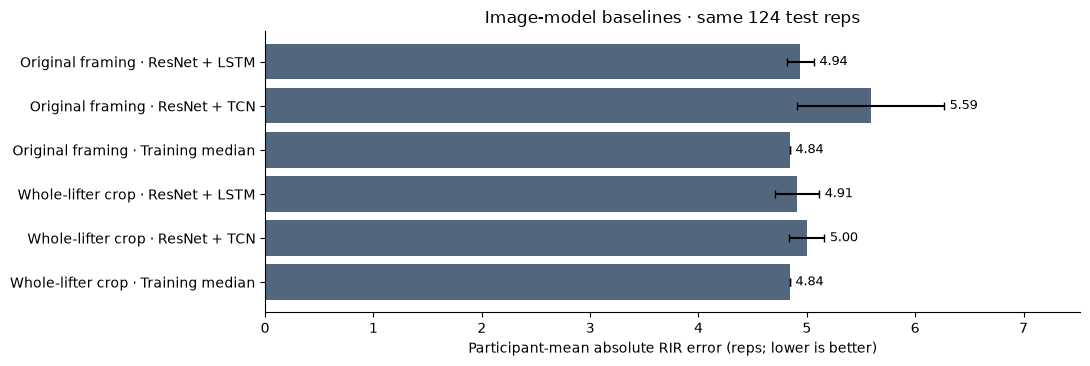

In [3]:
cropped_predictions = load_predictions(ROOT, "cropped", "Whole-lifter crop")
baseline_predictions = pd.concat([original_predictions, cropped_predictions], ignore_index=True)
assert_matched_examples(baseline_predictions)
baseline_scores, baseline_people = regression_report(baseline_predictions)
display(metrics_table(baseline_scores))
plot_errors(baseline_scores, "Image-model baselines · same 124 test reps", OUTPUT / "03_baselines.png")
plt.show()
baseline_scores.to_csv(OUTPUT / "03_baseline_metrics.csv", index=False)
baseline_people.to_csv(OUTPUT / "03_baseline_participants.csv", index=False)


**Result:** cropped LSTM MAE ≈ 4.91 and TCN ≈ 5.00. Cropping alone did not beat the 4.84 reference.  
**Next question:** would an encoder pretrained for video motion work better? See notebook 04.

## Reading the metrics

Metrics average each participant equally, then average training seeds. **MAE** is mean absolute error in reps; **RMSE** gives more weight to large errors. **Within 1/2** is the fraction within one/two reps. **Bias** is predicted minus known RIR: positive means too many reps predicted. R² compares with variation in known RIR; it can be negative and is undefined for a person with only one example. Seed standard deviation is not a confidence interval; one seed gives no estimate of training variability.

## Diagnostic · Can training fit one set?

**Why:** distinguish an optimization/wiring failure from poor transfer to new people.  
**Change:** deliberately fit and test on the same nine-rep set. This is **training-set memorization**, not a test result.

In [4]:
diagnostic_dir = result_folder(ROOT, "learning_check")
diagnostic_summary = json.loads((diagnostic_dir / "summary.json").read_text())
display(pd.DataFrame([{"initial_training_mae": diagnostic_summary["initial_training_mae"], "final_training_mae": diagnostic_summary["final_training_mae"], "reps": diagnostic_summary["reps"]}]).round(3))
curve = pd.read_csv(diagnostic_dir / "learning_curve.csv")
display(curve.tail(3))


,initial_training_mae,final_training_mae,reps
0,3.992,0.144,9


,epoch,training_mae_reps
5,60,0.748129
6,70,0.446067
7,80,0.143624


**Lesson:** the model can fit one set (training MAE ≈ 0.14), but that does not establish performance on new people. Do not rank this diagnostic alongside held-out results.

## Reproduce training · optional

Only enable the runs you need. Support cells are collapsed. The visible experiment loop retains the original training procedure; saved results above are not overwritten.

In [5]:
RUN_BASELINES = False
RUN_LEARNING_CHECK = False
EXPORT_DEMO_BUNDLE = False

In [6]:
if RUN_BASELINES or RUN_LEARNING_CHECK or EXPORT_DEMO_BUNDLE:
    from pathlib import Path
    from datetime import datetime, timezone
    from importlib.metadata import version
    import os
    os.environ["WANDB_DISABLE_CODE"] = "true"
    os.environ["WANDB_DISABLE_GIT"] = "true"
    os.environ["OTEL_SDK_DISABLED"] = "true"
    import copy
    import hashlib
    import json
    import random
    import time
    
    import cv2
    import numpy as np
    import pandas as pd
    import matplotlib
    matplotlib.use("module://matplotlib_inline.backend_inline")
    import matplotlib.pyplot as plt
    import torch
    from torch import nn
    from torch.nn import functional as F
    from torch.utils.data import Dataset, DataLoader
    from torchvision.models import resnet18, ResNet18_Weights
    import wandb
    from IPython.display import display
    
    RUN_MODE = "pilot"
    RESUME_RUN_DIR = None
    WANDB_MODE = "offline"
    WANDB_PROJECT = "replens-video-pilot"
    MODEL_NAMES = ["tcn", "lstm"]
    HIDDEN_SIZE = 64
    BATCH_SIZE = 4
    ENCODER_BATCH_SIZE = 16
    LEARNING_RATE = 0.001
    WEIGHT_DECAY = 0.0001
    PATIENCE = 5
    
    if RUN_MODE not in {"smoke", "pilot"} or WANDB_MODE not in {"offline", "online", "disabled"}:
        raise ValueError("Choose a supported run/tracking mode.")
    if not MODEL_NAMES or not set(MODEL_NAMES).issubset({"tcn", "lstm"}):
        raise ValueError("Choose tcn and/or lstm.")
    MAX_EPOCHS = 2 if RUN_MODE == "smoke" else 25
    SEEDS = [42] if RUN_MODE == "smoke" else [42, 43, 44]
    ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                 if (path / ".git").is_dir() and (path / "training" / "notebooks").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("Open this notebook from the RepLens project folder.")
    DATA_DIR = ROOT / "training" / "data"
    VIDEO_VARIANT = "cropped"
    VIDEO_DIR = DATA_DIR / ("cropped_videos" if VIDEO_VARIANT == "cropped" else "videos")
    MODEL_DIR = ROOT / "training" / "models"
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    torch.hub.set_dir(str(MODEL_DIR / "torch"))
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    cv2.setNumThreads(1)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    
    
    def sha256_file(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                digest.update(chunk)
        return digest.hexdigest()
    
    
    candidates = sorted((DATA_DIR / "prepared").glob("history_*_reps/*/preparation.json"), key=lambda path: path.stat().st_mtime, reverse=True)
    label_hash = sha256_file(DATA_DIR / "processed" / "reviewed_reps.csv")
    inventory_hash = sha256_file(DATA_DIR / "video_manifest.csv")
    PREPARATION_DIR = None
    for candidate in candidates:
        report = json.loads(candidate.read_text())
        config = report["configuration"]
        if (config["label_sha256"] == label_hash and config["inventory_sha256"] == inventory_hash
                and config.get("candidate_sha256") == sha256_file(DATA_DIR / "processed" / "candidate_reps.csv")
                and config.get("video_variant", "original") == VIDEO_VARIANT
                and (VIDEO_VARIANT != "cropped" or config.get("crop_exports_sha256") == sha256_file(DATA_DIR / "review/whole_lifter_crops/exports.json"))):
            PREPARATION_DIR = candidate.parent
            break
    if PREPARATION_DIR is None:
        raise RuntimeError("No preparation matches the current reviews. Run notebook 02 again.")
    print("Video framing:", VIDEO_VARIANT)
    windows = pd.read_csv(PREPARATION_DIR / "windows.csv")
    inference_windows = pd.read_csv(PREPARATION_DIR / "inference_windows.csv")
    if not inference_windows.empty and inference_windows.reps_left.notna().any():
        raise ValueError("Prediction-only windows must not contain training targets.")
    encoding_windows = pd.concat([windows, inference_windows], ignore_index=True)
    folds = json.loads((PREPARATION_DIR / "folds.json").read_text())
    with np.load(PREPARATION_DIR / "timestamps.npz", allow_pickle=False) as arrays:
        timestamps = {key: arrays[key].copy() for key in arrays.files}
    if RUN_MODE == "smoke":
        folds = folds[:1]
    if windows.empty or not np.isfinite(windows.reps_left).all():
        raise ValueError("Training windows/targets are missing or invalid.")
    DATASET_SCOPE = config.get("dataset_scope", "confirmed")
    accepted_labels = ["collector_confirmed_failure", "reviewer_confirmed_failure"]
    if DATASET_SCOPE == "exploratory":
        accepted_labels.append("user_reported_failure")
        print("EXPLORATORY: some targets use user-reported endpoints; public-source reuse permission is unverified.")
    if not windows.rir_label_status.isin(accepted_labels).all():
        raise ValueError("Resolve unsupported labels before training.")
    for _, group in encoding_windows.groupby("video_id"):
        source = (VIDEO_DIR / group.relative_path.iloc[0]).resolve()
        if not source.is_relative_to(VIDEO_DIR.resolve()) or sha256_file(source) != group.video_sha256.iloc[0]:
            raise ValueError("A source video changed after preparation.")
    for fold in folds:
        outer, test = set(fold["outer_train_participants"]), set(fold["test_participants"])
        if not outer.isdisjoint(test):
            raise ValueError("Participant leakage in outer folds.")
        for inner in fold["inner_validation"]:
            train, validation = set(inner["train_participants"]), set(inner["validation_participants"])
            if not train.isdisjoint(validation) or train | validation != outer:
                raise ValueError("Invalid inner validation split.")
    print(f"Mode: {RUN_MODE} | Device: {DEVICE} | Windows: {len(windows)} | Outer folds: {len(folds)}")
    print("Preparation:", PREPARATION_DIR.name)
    print(f"Prediction-only windows: {len(inference_windows)} across {inference_windows.video_id.nunique()} clips; excluded from training and accuracy.")
    
    print(f"Training dataset: {windows.video_id.nunique()} clips, {windows.participant_id.nunique()} people, {len(windows)} labeled reps.")


In [7]:
if RUN_BASELINES or RUN_LEARNING_CHECK or EXPORT_DEMO_BUNDLE:
    def prepare_frame(frame_bgr):
        height, width = frame_bgr.shape[:2]
        scale = 224 / max(height, width)
        resized = cv2.resize(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB),
                             (max(1, round(width * scale)), max(1, round(height * scale))), interpolation=cv2.INTER_AREA)
        canvas = np.empty((224, 224, 3), dtype=np.uint8)
        canvas[:] = [124, 116, 104]
        y, x = (224 - resized.shape[0]) // 2, (224 - resized.shape[1]) // 2
        canvas[y:y + resized.shape[0], x:x + resized.shape[1]] = resized
        tensor = torch.from_numpy(canvas).permute(2, 0, 1).float() / 255
        mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
        std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
        return (tensor - mean) / std
    
    
    weights = ResNet18_Weights.IMAGENET1K_V1
    encoder = resnet18(weights=weights)
    encoder.fc = nn.Identity()
    encoder.requires_grad_(False)
    encoder.eval().to(DEVICE)
    weight_path = Path(torch.hub.get_dir()) / "checkpoints" / Path(weights.url).name
    encoder_contract = {"encoder": "resnet18_imagenet1k_v1", "weights_sha256": sha256_file(weight_path),
                        "preprocessing": "rgb_aspect_pad_224_imagenet_normalization_v1", "temporal_downsampling": False,
                        "torch": str(torch.__version__), "torchvision": version("torchvision"), "opencv": cv2.__version__}
    encoder_id = hashlib.sha256(json.dumps(encoder_contract, sort_keys=True).encode()).hexdigest()[:16]
    FEATURE_DIR = DATA_DIR / "frame_embeddings" / encoder_id
    FEATURE_DIR.mkdir(parents=True, exist_ok=True)
    features = {}
    for video_id, group in encoding_windows.groupby("video_id", sort=False):
        row = group.iloc[0]
        cache = FEATURE_DIR / f"{row.video_sha256}.npz"
        expected = {"video_sha256": row.video_sha256, "encoder_id": encoder_id,
                    "frame_count": len(timestamps[video_id])}
        cached = None
        if cache.exists():
            try:
                with np.load(cache, allow_pickle=False) as saved:
                    if json.loads(str(saved["metadata"].item())) == expected:
                        candidate = saved["features"].copy()
                        if candidate.shape == (expected["frame_count"], 512) and np.isfinite(candidate).all():
                            cached = candidate
            except (OSError, ValueError, KeyError):
                pass
        if cached is None:
            print("Encoding:", row.relative_path, flush=True)
            capture = cv2.VideoCapture(str(VIDEO_DIR / row.relative_path))
            batches, pending = [], []
            decoded = 0
            try:
                with torch.inference_mode():
                    while True:
                        ok, frame = capture.read()
                        if not ok:
                            break
                        pending.append(prepare_frame(frame))
                        decoded += 1
                        if len(pending) == ENCODER_BATCH_SIZE:
                            batches.append(encoder(torch.stack(pending).to(DEVICE)).cpu().numpy())
                            pending.clear()
                        if decoded % 300 == 0:
                            print(f"  {decoded} frames", flush=True)
                    if pending:
                        batches.append(encoder(torch.stack(pending).to(DEVICE)).cpu().numpy())
            finally:
                capture.release()
            if not batches:
                raise ValueError(f"No readable frames: {video_id}")
            cached = np.concatenate(batches).astype(np.float32)
            if cached.shape != (expected["frame_count"], 512) or not np.isfinite(cached).all():
                raise ValueError("Encoded frames disagree with prepared timestamps.")
            temporary = cache.with_suffix(".tmp")
            try:
                with temporary.open("wb") as file:
                    np.savez_compressed(file, features=cached, metadata=np.array(json.dumps(expected, sort_keys=True)))
                temporary.replace(cache)
            finally:
                temporary.unlink(missing_ok=True)
        else:
            print("Reused encoded frames:", row.relative_path)
        features[video_id] = cached
    encoder.to("cpu")
    del encoder
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    print("Frozen frame encoding complete. Labels and participant IDs were not encoder inputs.")


In [8]:
if RUN_BASELINES or RUN_LEARNING_CHECK or EXPORT_DEMO_BUNDLE:
    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    
    
    class VideoWindows(Dataset):
        def __init__(self, table):
            self.table = table.reset_index(drop=True)
    
        def __len__(self):
            return len(self.table)
    
        def __getitem__(self, index):
            row = self.table.iloc[index]
            start, stop = int(row.frame_start), int(row.frame_stop_exclusive)
            values = features[row.video_id][start:stop]
            times = timestamps[row.video_id][start:stop]
            if not len(values) or len(values) != len(times) or times[-1] > row.clip_end_s or times[0] < row.clip_start_s:
                raise ValueError("Empty or noncausal video window.")
            return torch.from_numpy(values.copy()), float(row.reps_left)
    
    
    def collate_windows(batch):
        sequences, targets = zip(*batch)
        lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
        padded = nn.utils.rnn.pad_sequence(sequences, batch_first=True)
        return padded, lengths, torch.tensor(targets, dtype=torch.float32)
    
    
    def make_loader(table, shuffle, seed):
        generator = torch.Generator().manual_seed(seed)
        return DataLoader(VideoWindows(table), batch_size=BATCH_SIZE, shuffle=shuffle,
                          num_workers=0, collate_fn=collate_windows, generator=generator)
    
    
    class CausalBlock(nn.Module):
        def __init__(self, channels, dilation):
            super().__init__()
            self.padding = 2 * dilation
            self.conv = nn.Conv1d(channels, channels, kernel_size=3, dilation=dilation)
            self.dropout = nn.Dropout(0.1)
    
        def forward(self, values):
            return values + self.dropout(F.relu(self.conv(F.pad(values, (self.padding, 0)))))
    
    
    class TemporalRegressor(nn.Module):
        def __init__(self, family, hidden_size):
            super().__init__()
            self.family = family
            self.project = nn.Sequential(nn.LayerNorm(512), nn.Linear(512, hidden_size), nn.ReLU())
            if family == "tcn":
                self.temporal = nn.Sequential(*[CausalBlock(hidden_size, dilation) for dilation in [1, 2, 4, 8, 16]])
            elif family == "lstm":
                self.temporal = nn.LSTM(hidden_size, hidden_size, batch_first=True)
            else:
                raise ValueError("Unknown temporal model.")
            self.output = nn.Linear(hidden_size, 1)
    
        def forward(self, values, lengths):
            projected = self.project(values)
            if self.family == "tcn":
                encoded = self.temporal(projected.transpose(1, 2)).transpose(1, 2)
                mask = torch.arange(values.shape[1], device=values.device)[None, :] < lengths[:, None]
                pooled = (encoded * mask.unsqueeze(-1)).sum(dim=1) / lengths[:, None]
            else:
                encoded, _ = self.temporal(projected)
                pooled = encoded[torch.arange(len(values), device=values.device), lengths - 1]
            return self.output(pooled).squeeze(-1)
    
    
    def predict(model, table):
        model.eval()
        values = []
        with torch.inference_mode():
            for frames, lengths, _ in make_loader(table, False, 0):
                values.extend(model(frames.to(DEVICE), lengths.to(DEVICE)).cpu().numpy().tolist())
        output = np.asarray(values, dtype=float)
        if output.shape != (len(table),) or not np.isfinite(output).all():
            raise ValueError("Invalid model predictions.")
        return output
    
    
    def metrics(table, predictions):
        truth = table.reps_left.to_numpy(dtype=float)
        predictions = np.asarray(predictions, dtype=float)
        if truth.shape != predictions.shape or not np.isfinite(predictions).all():
            raise ValueError("Each example requires one finite prediction.")
        error = predictions - truth
        person = pd.DataFrame({"participant": table.participant_id.to_numpy(), "absolute_error": np.abs(error)})
        return {"mae_reps": float(np.abs(error).mean()),
                "participant_mean_mae_reps": float(person.groupby("participant").absolute_error.mean().mean()),
                "rmse_reps": float(np.sqrt(np.mean(error ** 2))), "within_one_rep": float((np.abs(error) <= 1).mean()),
                "signed_error_reps": float(error.mean())}
    
    
    def fit_head(family, train_table, validation_table, epochs, seed, run, stage):
        set_seed(seed)
        model = TemporalRegressor(family, HIDDEN_SIZE).to(DEVICE)
        with torch.no_grad():
            model.output.bias.fill_(float(train_table.reps_left.mean()))
        optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        criterion = nn.SmoothL1Loss()
        history, best_state = [], None
        best_score, best_epoch, waiting = float("inf"), 0, 0
        run.define_metric(f"{stage}/epoch")
        run.define_metric(f"{stage}/*", step_metric=f"{stage}/epoch")
        for epoch in range(1, epochs + 1):
            model.train()
            loss_total, count = 0.0, 0
            for frames, lengths, targets in make_loader(train_table, True, seed + epoch):
                optimizer.zero_grad(set_to_none=True)
                prediction = model(frames.to(DEVICE), lengths.to(DEVICE))
                loss = criterion(prediction, targets.to(DEVICE))
                if not torch.isfinite(loss):
                    raise ValueError("Training loss became nonfinite.")
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                loss_total += float(loss.detach().cpu()) * len(targets)
                count += len(targets)
            entry = {"stage": stage, "epoch": epoch, "train_loss": loss_total / count}
            log = {f"{stage}/epoch": epoch, f"{stage}/train_loss": entry["train_loss"]}
            if validation_table is not None:
                score = metrics(validation_table, predict(model, validation_table))["participant_mean_mae_reps"]
                entry["validation_mae_reps"] = score
                log[f"{stage}/validation_mae_reps"] = score
                if score < best_score - 1e-4:
                    best_score, best_epoch, waiting = score, epoch, 0
                    best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
                else:
                    waiting += 1
            run.log(log)
            history.append(entry)
            if validation_table is not None and waiting >= PATIENCE:
                break
        if validation_table is not None:
            if best_state is None:
                raise ValueError("No finite validation checkpoint.")
            model.load_state_dict(best_state)
        else:
            best_epoch = epochs
        return model, best_epoch, history


In [9]:
if RUN_BASELINES:
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    RUN_DIR = ROOT / "training" / "artifacts" / f"{RUN_MODE}_{run_id}"
    if RESUME_RUN_DIR is not None:
        RUN_DIR = Path(RESUME_RUN_DIR).resolve()
        if not RUN_DIR.is_relative_to((ROOT / "training" / "artifacts").resolve()) or not RUN_DIR.is_dir():
            raise ValueError("Resume must reference an existing local training run.")
        run_id = RUN_DIR.name.removeprefix(f"{RUN_MODE}_")
    else:
        RUN_DIR.mkdir(parents=True, exist_ok=False)
    settings = wandb.Settings(disable_git=True, disable_code=True, save_code=False, x_disable_stats=True)
    experiment_config = {"mode": RUN_MODE, "dataset_scope": DATASET_SCOPE, "video_variant": VIDEO_VARIANT, "preparation_id": PREPARATION_DIR.name,
                         "encoder": encoder_contract, "hidden_size": HIDDEN_SIZE, "batch_size": BATCH_SIZE,
                         "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "patience": PATIENCE,
                         "max_epochs": MAX_EPOCHS, "seeds": SEEDS, "models": MODEL_NAMES,
                         "labeled_videos": int(windows.video_id.nunique()), "prediction_only_videos": int(inference_windows.video_id.nunique()),
                         "versions": {name: version(name) for name in ["torch", "torchvision", "wandb", "numpy", "pandas"]}}
    if RESUME_RUN_DIR is not None:
        if json.loads((RUN_DIR / "config.json").read_text()) != experiment_config:
            raise ValueError("Resume configuration/data differ from the saved run. Start a new run.")
    else:
        (RUN_DIR / "config.json").write_text(json.dumps(experiment_config, indent=2) + "\n")
    prediction_tables, histories, inference_tables = [], [], []
    if RESUME_RUN_DIR is not None and (RUN_DIR / "history.csv").exists():
        histories = pd.read_csv(RUN_DIR / "history.csv").to_dict("records")
    for fold_number, fold in enumerate(folds, start=1):
        outer_train = windows[windows.participant_id.isin(fold["outer_train_participants"])].copy()
        test = windows[windows.participant_id.isin(fold["test_participants"])].copy()
        for seed in SEEDS:
            baseline = test[["sample_id", "participant_id", "video_id", "set_id", "rep", "reps_left"]].copy()
            baseline["prediction"] = float(outer_train.reps_left.median())
            baseline["model"], baseline["seed"], baseline["fold_id"] = "training_median", seed, fold["fold_id"]
            prediction_tables.append(baseline)
            for family in MODEL_NAMES:
                print(f"{RUN_MODE}: fold {fold_number}/{len(folds)}, {family}, seed {seed}", flush=True)
                checkpoint_path = RUN_DIR / f"{family}_{fold['fold_id']}_seed{seed}.pt"
                resumed = RESUME_RUN_DIR is not None and checkpoint_path.exists()
                run = None if resumed else wandb.init(project=WANDB_PROJECT, mode=WANDB_MODE, dir=str(RUN_DIR),
                                 group=f"{RUN_MODE}_{run_id}", name=f"{family}_fold{fold_number}_seed{seed}",
                                 config={**experiment_config, "model": family, "fold_number": fold_number, "seed": seed},
                                 settings=settings, save_code=False, tags=[RUN_MODE, family])
                try:
                    if resumed:
                        with torch.serialization.safe_globals([torch.torch_version.TorchVersion]):
                            checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
                        if checkpoint["preparation_id"] != PREPARATION_DIR.name or checkpoint["encoder_contract"] != encoder_contract:
                            raise ValueError("Checkpoint belongs to a different dataset/encoder.")
                        model = TemporalRegressor(family, HIDDEN_SIZE).to(DEVICE)
                        model.load_state_dict(checkpoint["state_dict"])
                        final_epochs = checkpoint["refit_epochs"]
                        print("  Reused completed checkpoint", flush=True)
                    else:
                        best_epochs = []
                        for inner_number, inner in enumerate(fold["inner_validation"], start=1):
                            train = windows[windows.participant_id.isin(inner["train_participants"])].copy()
                            validation = windows[windows.participant_id.isin(inner["validation_participants"])].copy()
                            model, best_epoch, history = fit_head(family, train, validation, MAX_EPOCHS, seed, run, f"inner_{inner_number}")
                            best_epochs.append(best_epoch)
                            histories.extend([{**entry, "model": family, "seed": seed, "fold_id": fold["fold_id"]} for entry in history])
                            del model
                        final_epochs = max(1, int(round(float(np.median(best_epochs)))))
                        model, _, history = fit_head(family, outer_train, None, final_epochs, seed, run, "outer_refit")
                        histories.extend([{**entry, "model": family, "seed": seed, "fold_id": fold["fold_id"]} for entry in history])
                    predicted = predict(model, test)
                    if not inference_windows.empty:
                        extra = inference_windows[["sample_id", "video_id", "participant_id", "set_id", "rep", "rir_label_status"]].copy()
                        extra["prediction"] = predict(model, inference_windows)
                        extra["model"], extra["seed"], extra["fold_id"] = family, seed, fold["fold_id"]
                        extra["prediction_status"] = "experimental_unvalidated"
                        inference_tables.append(extra)
                    scores = metrics(test, predicted)
                    if run is not None:
                        run.log({f"test/{key}": value for key, value in scores.items()})
                    if run is not None:
                        run.summary.update({"refit_epochs": final_epochs, "trainable_parameters": sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad), **scores})
                    table = test[["sample_id", "participant_id", "video_id", "set_id", "rep", "reps_left"]].copy()
                    table["prediction"], table["model"], table["seed"], table["fold_id"] = predicted, family, seed, fold["fold_id"]
                    prediction_tables.append(table)
                    checkpoint = {"state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
                                  "family": family, "hidden_size": HIDDEN_SIZE, "encoder_contract": encoder_contract,
                                  "preparation_id": PREPARATION_DIR.name, "mode": RUN_MODE, "seed": seed,
                                  "outer_fold": fold, "refit_epochs": final_epochs, "deployment_approved": False}
                    temporary_checkpoint = checkpoint_path.with_suffix(".tmp")
                    torch.save(checkpoint, temporary_checkpoint)
                    temporary_checkpoint.replace(checkpoint_path)
                    print(f"  Held-out MAE: {scores['participant_mean_mae_reps']:.3f} reps", flush=True)
                    del model
                finally:
                    if run is not None:
                        run.finish()
                pd.concat(prediction_tables, ignore_index=True).to_csv(RUN_DIR / "predictions.csv", index=False)
                pd.DataFrame(histories).to_csv(RUN_DIR / "history.csv", index=False)
                if inference_tables:
                    pd.concat(inference_tables, ignore_index=True).to_csv(RUN_DIR / "unlabeled_predictions.csv", index=False)
    predictions = pd.concat(prediction_tables, ignore_index=True)
    print("Completed:", RUN_DIR.relative_to(ROOT))


In [10]:
if RUN_BASELINES:
    seed_scores = []
    for (family, seed), group in predictions.groupby(["model", "seed"]):
        seed_scores.append({"model": family, "seed": int(seed), **metrics(group, group.prediction.to_numpy())})
    seed_scores = pd.DataFrame(seed_scores)
    comparison = seed_scores.groupby("model").agg(
        participant_mae_mean=("participant_mean_mae_reps", "mean"),
        participant_mae_seed_std=("participant_mean_mae_reps", lambda values: float(values.std(ddof=0))),
        rmse_mean=("rmse_reps", "mean"), within_one_rep_mean=("within_one_rep", "mean"), seeds=("seed", "nunique"),
    )
    comparison.to_csv(RUN_DIR / "comparison.csv")
    seed_scores.to_csv(RUN_DIR / "seed_scores.csv", index=False)
    display(comparison)
    axes = comparison.participant_mae_mean.plot.bar(yerr=comparison.participant_mae_seed_std, capsize=4, rot=0, figsize=(7, 4))
    axes.set(ylabel="Participant-mean MAE (reps)", title=f"{RUN_MODE.upper()}: architecture comparison")
    plt.tight_layout()
    plt.show()
    plt.close(axes.figure)
    print("Saved predictions, learning curves, comparisons and temporal-head checkpoints locally.")
    if inference_tables:
        extra_predictions = pd.concat(inference_tables, ignore_index=True)
        preview = extra_predictions.groupby(["video_id", "rep", "model"], as_index=False).prediction.mean()
        display(preview.head(20))
        print("unlabeled_predictions.csv contains experimental predictions, not verified RIR labels. No accuracy claim is made for these clips.")
    
    if DATASET_SCOPE == "exploratory":
        print("Scores depend on user-reported endpoints and automatic rep counts. They do not independently validate physiological fatigue.")


In [11]:
if RUN_LEARNING_CHECK:
    diagnostic_dir = ROOT / "training/artifacts" / ("learning_check_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
    diagnostic_dir.mkdir()
    table = windows.loc[windows.rir_label_status.eq("collector_confirmed_failure")].copy()
    video_id = table.video_id.iloc[0]
    table = table.loc[table.video_id.eq(video_id)].sort_values("rep")
    set_seed(42)
    model = TemporalRegressor("tcn", HIDDEN_SIZE).to(DEVICE)
    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.p = 0
    optimizer = torch.optim.Adam(model.parameters(), lr=.003)
    curve = []
    initial = predict(model, table)
    initial_score = float(np.mean(np.abs(initial - table.reps_left.to_numpy())))
    for epoch in range(1, 401):
        model.train()
        for values, lengths, targets in make_loader(table, True, 42 + epoch):
            optimizer.zero_grad(set_to_none=True)
            loss = F.mse_loss(model(values.to(DEVICE), lengths.to(DEVICE)), targets.to(DEVICE))
            if not torch.isfinite(loss):
                raise ValueError("Nonfinite diagnostic loss.")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5)
            optimizer.step()
        if epoch % 10 == 0:
            predictions = predict(model, table)
            score = float(np.mean(np.abs(predictions - table.reps_left.to_numpy())))
            curve.append({"epoch":epoch, "training_mae_reps":score})
            print(f"One-set check epoch {epoch}: train MAE {score:.3f}", flush=True)
            if score < .25:
                break
    output = table[["video_id","rep","reps_left"]].copy()
    output["prediction"] = predict(model, table)
    final_score = float(np.mean(np.abs(output.prediction-output.reps_left)))
    output.to_csv(diagnostic_dir / "predictions.csv",index=False)
    pd.DataFrame(curve).to_csv(diagnostic_dir / "learning_curve.csv",index=False)
    report = {"video_id":video_id,"reps":len(table),"initial_training_mae":initial_score,
              "final_training_mae":final_score,"passed":bool(final_score<.5),
              "note":"Deliberate training-set memorization only; no generalization claim.","epochs":epoch}
    (diagnostic_dir / "summary.json").write_text(json.dumps(report,indent=2)+"\n")
    print(json.dumps(report,indent=2));display(output)
else:
    print("Enable RUN_LEARNING_CHECK for an isolated one-set optimization diagnostic.")


Enable RUN_LEARNING_CHECK for an isolated one-set optimization diagnostic.


In [12]:
if EXPORT_DEMO_BUNDLE and not RUN_BASELINES:
    RUN_DIR = ROOT / "training/artifacts" / RUNS["cropped"]
if EXPORT_DEMO_BUNDLE:
    import sys
    from datetime import datetime, timezone
    source_dir = RUN_DIR
    scores = pd.read_csv(source_dir / "comparison.csv").set_index("model")
    family = scores.loc[["tcn", "lstm"], "participant_mae_mean"].idxmin()
    checkpoints = [torch.load(p, map_location="cpu", weights_only=True)
                   for p in source_dir.glob(f"{family}_test_*_seed*.pt")]
    if len(checkpoints) != len(folds) * len(SEEDS):
        raise RuntimeError("Complete participant/seed evaluation before preparing a demo bundle.")
    epochs = max(1, int(np.median([c["refit_epochs"] for c in checkpoints])))
    run = wandb.init(project=WANDB_PROJECT, mode="offline", name="all-data-demo-refit", dir=str(source_dir),
                     config={"family":family, "epochs":epochs, "seed":42, "evaluated":False})
    try:
        model, _, _ = fit_head(family, windows, None, epochs, 42, run, "demo_refit")
    finally:
        run.finish()
    metadata = {"family":family, "hidden_size":HIDDEN_SIZE,
                "version":source_dir.name, "experimental":True, "evaluated_refit":False,
                "participant_mae_reps":float(scores.loc[family,"participant_mae_mean"]),
                "baseline_participant_mae_reps":float(scores.loc["training_median","participant_mae_mean"]),
                "history_reps":4, "seed":42, "refit_epochs":epochs,
                "training_reps":len(windows), "training_participants":windows.participant_id.nunique(),
                "preprocessing":encoder_contract["preprocessing"],
                "encoder_weights_sha256":encoder_contract["weights_sha256"],
                "created_at":datetime.now(timezone.utc).isoformat(),
                "label_scope":DATASET_SCOPE, "video_variant":VIDEO_VARIANT, "intended_use":"experimental demonstration only"}
    folder = MODEL_DIR / "demo"
    folder.mkdir(exist_ok=True)
    temporary = folder / "model.tmp"
    torch.save({"state_dict":{k:v.detach().cpu() for k,v in model.state_dict().items()},
                "metadata":metadata, "deployment_approved":False}, temporary)
    temporary.replace(folder / "model.pt")
    (folder / "metadata.json").write_text(json.dumps(metadata,indent=2)+"\n")
    print("Saved experimental demo bundle:", folder)
    print("Neural held-out MAE:",metadata["participant_mae_reps"],"baseline:",metadata["baseline_participant_mae_reps"])
else:
    print("Set EXPORT_DEMO_BUNDLE=True only when preparing an experimental application bundle.")


Set EXPORT_DEMO_BUNDLE=True only when preparing an experimental application bundle.
